In [7]:
import os
import numpy as np
from sklearn.model_selection import KFold
from sklearn.metrics import accuracy_score, confusion_matrix
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader, Subset
import torchvision.transforms as transforms
from torchvision.datasets import ImageFolder
import matplotlib.pyplot as plt
import seaborn as sns

In [8]:
# Seed for reproducibility
np.random.seed(42)
torch.manual_seed(42)

# Dataset path
DATASET_PATH = "Celebrity Faces Dataset"

# Define transformations for dataset
transform = transforms.Compose([
    transforms.Resize((128, 128)),  # Resize all images to the same size
    transforms.ToTensor(),  # Convert images to PyTorch tensors
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])  # Normalize using ImageNet stats
])

In [9]:
# Load dataset
dataset = ImageFolder(root=DATASET_PATH, transform=transform)
class_names = dataset.classes # Class names for confusion matrix and plot
num_classes = len(class_names)

In [10]:
# Device configuration
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print('Using device:', device)

Using device: cuda


In [11]:
dataset

Dataset ImageFolder
    Number of datapoints: 1800
    Root location: Celebrity Faces Dataset
    StandardTransform
Transform: Compose(
               Resize(size=(128, 128), interpolation=bilinear, max_size=None, antialias=True)
               ToTensor()
               Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
           )

In [6]:
# Define CNN model
class FaceRecognitionCNN(nn.Module):
    def __init__(self, num_classes):
        super(FaceRecognitionCNN, self).__init__()
        self.conv_layers = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )
        self.fc_layers = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 16 * 16, 256),
            nn.ReLU(),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        x = self.conv_layers(x)
        x = self.fc_layers(x)
        return x

model = FaceRecognitionCNN(num_classes).to(device)

In [7]:
# Initialize model, loss, and optimizer
model = FaceRecognitionCNN(num_classes).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

# 10-fold Leave-One-Out Cross-Validation (LOOCV)
kf = KFold(n_splits=10, shuffle=True, random_state=42)
folds = list(kf.split(range(len(dataset))))

accuracies = []
conf_matrix = np.zeros((num_classes, num_classes))

In [8]:
for fold_idx, (train_idx, test_idx) in enumerate(folds):
    print(f"Processing Fold {fold_idx + 1}")
    train_set = Subset(dataset, train_idx)
    test_set = Subset(dataset, test_idx)

    train_loader = DataLoader(train_set, batch_size=32, shuffle=True)
    test_loader = DataLoader(test_set, batch_size=32, shuffle=False)

    # Training
    model.train()
    for epoch in range(10): # 10 Epochs but adjustable
        total_loss = 0.0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()  # Reset gradients
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()  # Backpropagation
            optimizer.step()

            total_loss += loss.item()
        print(f"Epoch [{epoch + 1}/10], Loss: {total_loss / len(train_loader):.3f}")

    # Evaluation
    model.eval()
    all_preds = []
    all_labels = []
    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, preds = torch.max(outputs, 1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    # Calculate accuracy and confusion matrix for this fold
    fold_accuracy = accuracy_score(all_labels, all_preds)
    accuracies.append(fold_accuracy)
    fold_conf_matrix = confusion_matrix(all_labels, all_preds, labels=range(num_classes))
    conf_matrix += fold_conf_matrix

Processing Fold 1
Epoch [1/10], Loss: 2.715
Epoch [2/10], Loss: 2.254
Epoch [3/10], Loss: 1.895
Epoch [4/10], Loss: 1.365
Epoch [5/10], Loss: 0.770
Epoch [6/10], Loss: 0.324
Epoch [7/10], Loss: 0.140
Epoch [8/10], Loss: 0.090
Epoch [9/10], Loss: 0.043
Epoch [10/10], Loss: 0.041
Processing Fold 2
Epoch [1/10], Loss: 0.533
Epoch [2/10], Loss: 0.077
Epoch [3/10], Loss: 0.010
Epoch [4/10], Loss: 0.002
Epoch [5/10], Loss: 0.001
Epoch [6/10], Loss: 0.001
Epoch [7/10], Loss: 0.000
Epoch [8/10], Loss: 0.000
Epoch [9/10], Loss: 0.000
Epoch [10/10], Loss: 0.000
Processing Fold 3
Epoch [1/10], Loss: 0.008
Epoch [2/10], Loss: 0.025
Epoch [3/10], Loss: 0.060
Epoch [4/10], Loss: 0.109
Epoch [5/10], Loss: 0.045
Epoch [6/10], Loss: 0.014
Epoch [7/10], Loss: 0.009
Epoch [8/10], Loss: 0.023
Epoch [9/10], Loss: 0.016
Epoch [10/10], Loss: 0.003
Processing Fold 4
Epoch [1/10], Loss: 0.022
Epoch [2/10], Loss: 0.034
Epoch [3/10], Loss: 0.038
Epoch [4/10], Loss: 0.007
Epoch [5/10], Loss: 0.009
Epoch [6/10], L

In [9]:
# Final Results
average_accuracy = np.mean(accuracies)
print(f"Average Accuracy: {average_accuracy:.4f}")

Average Accuracy: 0.9356


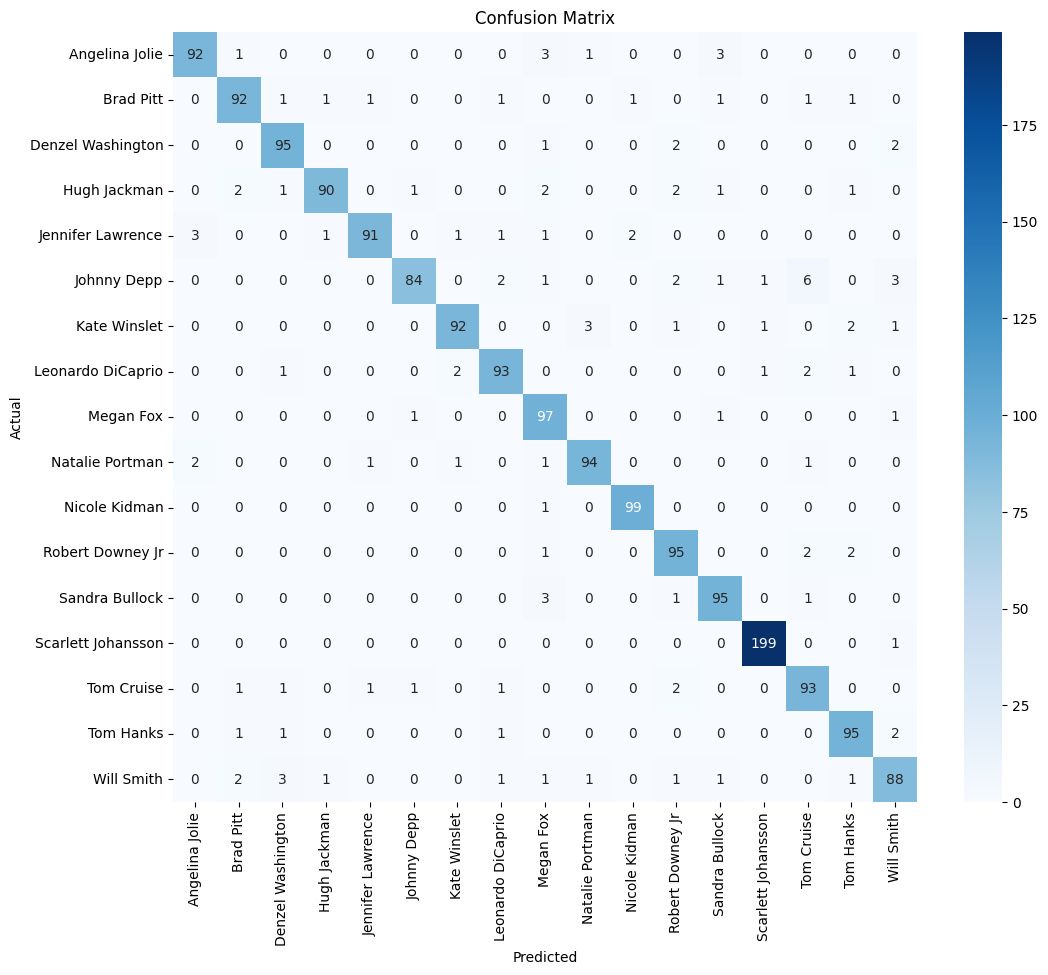

In [10]:
# Plot confusion matrix
plt.figure(figsize=(12, 10))
sns.heatmap(conf_matrix, annot=True, fmt="g", xticklabels=class_names, yticklabels=class_names, cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()